### Homework 05 - Volume estimate using Monte Carlo method
Igor Di Tota

**Introduction**

In this exercise, the Monte Carlo method is used to compute the volume of a solid defined as the intersection of three cones placed inside the unit cube $[0,1]^3$.

Each cone has unit height and unit base diameter.
The axes of the three cones are mutually perpendicular.

The solid considered is the set of points belonging to all three cones at the same time.
The volume is estimated by generating random points uniformly inside the cube and counting the fraction that falls inside the solid.

The work is organised as follows:
- definition of the geometry and of the conditions for a point to be inside each cone;
- validation of the method on a single cone;
- estimate of the volume of the intersection and of its statistical uncertainty;
- study of the convergence of the estimate as a function of the number of generated points.


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import os
os.makedirs("images", exist_ok=True)
from itertools import product, combinations

rng = np.random.default_rng(23)

### Geometry of the problem

A Cartesian reference frame is chosen with the cube occupying the region $[0,1]^3$.
For a cone with axis along the coordinate $x_k$ ($k = 0, 1, 2$ for $x, y, z$), the base of radius $R = 1/2$ lies on the face $x_k = 0$ and the apex is at the centre of the face $x_k = 1$ since height $H = 1$.

Let $t = x_k$ be the coordinate along the axis and $(u, v)$ the two remaining coordinates.
At height $t$, the cross-section of the cone is a disc centred on the axis, $(u, v) = (1/2, 1/2)$, whose radius decreases linearly from $R$ at the base to $0$ at the apex:
$$
r(t) = R \left(1 - \frac{t}{H}\right).
$$
A point $(x, y, z)$ is therefore inside the cone if its distance from the axis does not exceed $r(t)$:
$$
\left(u - \tfrac{1}{2}\right)^2 + \left(v - \tfrac{1}{2}\right)^2 \le R^2 \left(1 - \frac{t}{H}\right)^2 .
$$

Explicitly, for the three cones:
$$
\begin{aligned}
\text{cone } x: &\quad (y - \tfrac12)^2 + (z - \tfrac12)^2 \le \tfrac14 (1 - x)^2, \\
\text{cone } y: &\quad (z - \tfrac12)^2 + (x - \tfrac12)^2 \le \tfrac14 (1 - y)^2, \\
\text{cone } z: &\quad (x - \tfrac12)^2 + (y - \tfrac12)^2 \le \tfrac14 (1 - z)^2 .
\end{aligned}
$$
The solid is the set of points satisfying all three conditions at the same time.

### Implementation

The functions below are written for a cone with a generic axis $x_k$, where $k = 0, 1, 2$ stands for $x, y, z$.
In this way, the same code can be reused for all three cones by changing the index $k$.
The two coordinates perpendicular to the axis are obtained cyclically as $x_{(k+1) \bmod 3}$ and $x_{(k+2) \bmod 3}$.

The function `inside` takes an array of points of shape $(3, N)$ and applies the condition derived above and it returns a boolean mask that is `True` for the points inside the cone.
The intersection of the three cones is then simply the logical AND of the three masks.
The option `flip` moves the base to the opposite face, replacing $t \to 1 - t$.

The lateral surface of the cone is described in parametric form, with the coordinate along the axis $t$ and the azimuthal angle $\varphi$ around the axis:
$$
t \in [0, H], \quad \varphi \in [0, 2\pi]: \qquad
x_k = t, \quad
u = \tfrac12 + r(t)\cos\varphi, \quad
v = \tfrac12 + r(t)\sin\varphi ,
$$
with $r(t) = R\,(1 - t/H)$.
On a grid of values of $(t, \varphi)$, the three coordinates are computed and placed in the correct order according to the direction of the axis.
The function `plot_cube` draws the edges of the cube.
Each edge joins two vertices that differ in exactly one coordinate.


In [50]:
# Cone dimensions
R = 0.5
H = 1.0

def inside(points, axis, flip=False):
    "Mask of the points inside the cone with axis along coordinate `axis`"
    t = points[axis]
    if flip:
        t = 1 - t
    u = points[(axis + 1) % 3]
    v = points[(axis + 2) % 3]
    r2 = (u - 0.5)**2 + (v - 0.5)**2
    return r2 <= (R * (1 - t / H))**2


def plot_cone(ax, axis, flip=False, color="tab:red", alpha=0.4, n_phi=200):
    "Draws the lateral surface of the cone with axis along coordinate `axis`."
    t, phi = np.meshgrid(np.linspace(0, H, 2), np.linspace(0, 2 * np.pi, n_phi))
    r = R * (1 - t / H)
    coords = np.empty((3,) + t.shape)
    if flip:
        coords[axis] = 1 - t
    else:
        coords[axis] = t
    coords[(axis + 1) % 3] = 0.5 + r * np.cos(phi)
    coords[(axis + 2) % 3] = 0.5 + r * np.sin(phi)
    ax.plot_surface(*coords, color=color, alpha=alpha, rstride=1, cstride=1,
                    linewidth=0, antialiased=True, shade=True)



def plot_cube(ax, color="silver", linewidth=0.6):
    """Draws the 12 edges of the unit cube."""
    for a in [0, 1]:
        for b in [0, 1]:
            ax.plot([0, 1], [a, a], [b, b], color=color, linewidth=linewidth)   # edges along x
            ax.plot([a, a], [0, 1], [b, b], color=color, linewidth=linewidth)   # edges along y
            ax.plot([a, a], [b, b], [0, 1], color=color, linewidth=linewidth)   # edges along z


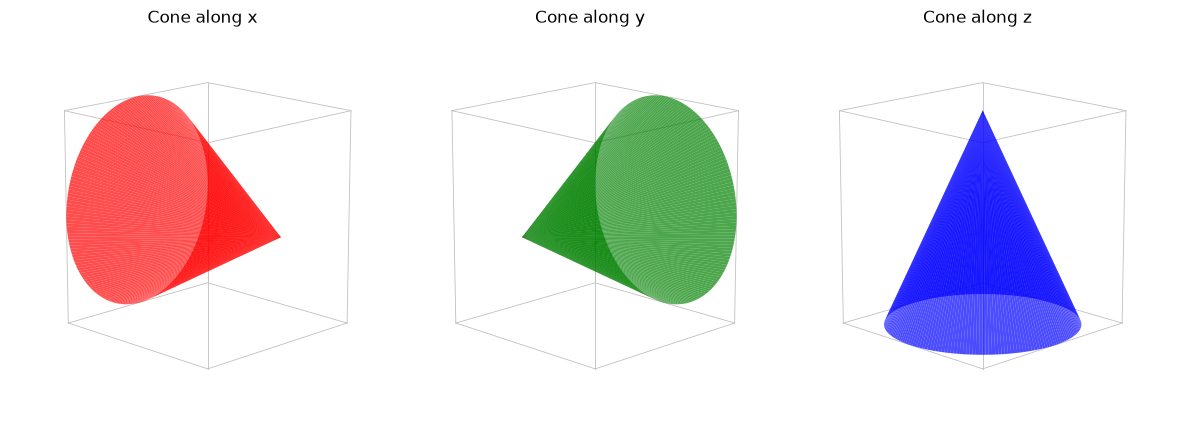

In [67]:
cones = [(0, "red", False), (1, "green", True), (2, "blue", False)]
alp = 0.7
axis_names = ["x", "y", "z"]

fig = plt.figure(figsize=(15, 5))
for k, (axis, color, flip) in enumerate(cones):
    ax = fig.add_subplot(1, 3, k + 1, projection="3d")
    plot_cube(ax)
    plot_cone(ax, axis, color=color, flip=flip, alpha=alp)

    ax.set_box_aspect((1, 1, 1))
    ax.set_axis_off()
    ax.view_init(elev=15, azim=-45)
    ax.set_title(f"Cone along {axis_names[axis]}")

fig.subplots_adjust(wspace=0)
fig.savefig("images/single_cones.pdf", bbox_inches="tight")
plt.show()


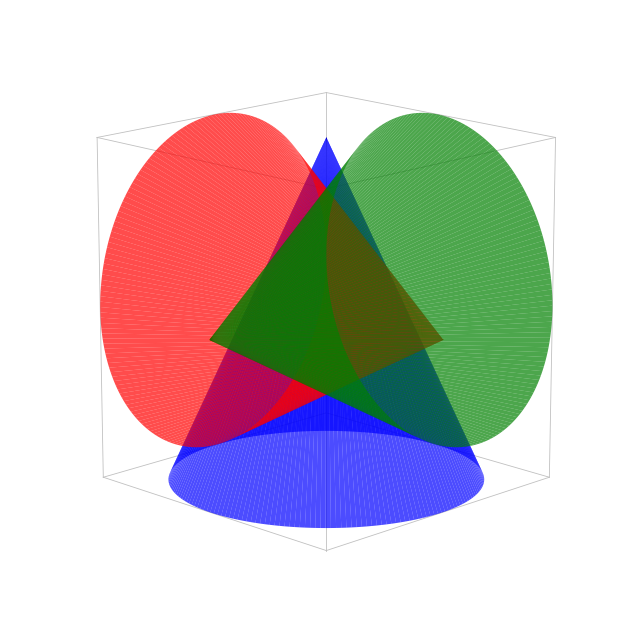

In [68]:
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(projection="3d")
plot_cube(ax)
for axis, color, flip in cones:
    plot_cone(ax, axis, color=color, flip=flip, alpha=alp)

ax.set_box_aspect((1, 1, 1))
ax.set_axis_off()
ax.view_init(elev=15, azim=-45)
fig.savefig("images/cones.pdf", bbox_inches="tight")
plt.show()
